<a href="https://colab.research.google.com/github/dou3aa-ux/DevFlow/blob/main/Plant_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Tomato images to extract: 18160
Loaded images: 18160
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


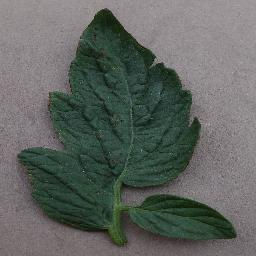

In [7]:
from huggingface_hub import hf_hub_download
from zipfile import ZipFile
from pathlib import Path
from torchvision.datasets import ImageFolder
from PIL import Image

zip_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="data.zip",
)

extract_to = Path("/content/plantvillage_tomato")
tomato_prefix = "raw/color/Tomato"

with ZipFile(zip_path) as archive:
    tomato_files = [
        name for name in archive.namelist()
        if name.startswith(tomato_prefix)
        and name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print("Tomato images to extract:", len(tomato_files))

    for name in tomato_files:
        archive.extract(name, extract_to)

data_root = extract_to / "raw" / "color"
tomato_data = ImageFolder(str(data_root))

print("Loaded images:", len(tomato_data))
print("Classes:", tomato_data.classes)

image_path, label = tomato_data.samples[0]
display(Image.open(image_path))

In [8]:
from huggingface_hub import hf_hub_download
from pathlib import Path

train_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="splits/color_train.txt",
)

test_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="splits/color_test.txt",
)

def read_tomato_paths(filename):
    with open(filename, "r") as f:
        return {
            line.strip()
            for line in f
            if line.strip().startswith("raw/color/Tomato")
        }

official_train = read_tomato_paths(train_file)
official_test = read_tomato_paths(test_file)

available = {
    Path(path).relative_to(extract_to).as_posix()
    for path, _ in tomato_data.samples
}

train_paths = official_train & available
test_paths = official_test & available

print("Train images:", len(train_paths))
print("Test images:", len(test_paths))
print("Images missing from split lists:", len(available - train_paths - test_paths))
print("Train/test overlap:", len(train_paths & test_paths))

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

Train images: 14521
Test images: 3639
Images missing from split lists: 0
Train/test overlap: 0


In [10]:
import json
import numpy as np
from pathlib import Path
from huggingface_hub import hf_hub_download
from sklearn.model_selection import StratifiedGroupKFold

leaf_map_file = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="leaf_grouping/leaf-map.json",
)

with open(leaf_map_file, "r") as f:
    leaf_map = json.load(f)

all_train_rows = []

for image_path, label in tomato_data.samples:
    relative_path = Path(image_path).relative_to(extract_to).as_posix()

    if relative_path not in train_paths:
        continue

    class_name = Path(relative_path).parent.name
    image_id = Path(relative_path).name.replace("_final_masked", "")

    if "___" in image_id:
        image_id = image_id.split("___")[-1]

    image_id = image_id.split("copy")[0]
    image_id = Path(image_id).stem.strip()

    suggestions = leaf_map.get(image_id.lower(), [])

    if len(suggestions) == 1:
        group_id = suggestions[0]
    else:
        group_id = next(
            (item for item in suggestions if class_name in item),
            f"fallback_{image_id}",
        )

    all_train_rows.append({
        "path": image_path,
        "label": label,
        "group": group_id,
    })

y = np.array([row["label"] for row in all_train_rows])
groups = np.array([row["group"] for row in all_train_rows])

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

train_idx, val_idx = next(
    splitter.split(np.zeros(len(y)), y, groups)
)

train_rows = [all_train_rows[i] for i in train_idx]
val_rows = [all_train_rows[i] for i in val_idx]

train_groups = {row["group"] for row in train_rows}
val_groups = {row["group"] for row in val_rows}

print("Training images:", len(train_rows))
print("Validation images:", len(val_rows))
print("Shared leaf groups:", len(train_groups & val_groups))

Training images: 11609
Validation images: 2912
Shared leaf groups: 0


In [11]:
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Build rows for the official test set
test_rows = []

for image_path, label in tomato_data.samples:
    relative_path = Path(image_path).relative_to(extract_to).as_posix()

    if relative_path in test_paths:
        test_rows.append({
            "path": image_path,
            "label": label,
        })

class LeafDataset(Dataset):
    def __init__(self, rows, transform=None):
        self.rows = rows
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image = Image.open(row["path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, row["label"]

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_loader = DataLoader(
    LeafDataset(train_rows, train_transform),
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_loader = DataLoader(
    LeafDataset(val_rows, eval_transform),
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    LeafDataset(test_rows, eval_transform),
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

images, labels = next(iter(train_loader))

print("Test images:", len(test_rows))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Classes:", tomato_data.classes)


Test images: 3639
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(tomato_data.classes)

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

images, labels = next(iter(train_loader))

with torch.no_grad():
    scores = model(images.to(device))

print("Device:", device)
print("Output shape:", scores.shape)
print("Number of classes:", num_classes)

In [12]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(tomato_data.classes)

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

images, labels = next(iter(train_loader))

with torch.no_grad():
    scores = model(images.to(device))

print("Device:", device)
print("Output shape:", scores.shape)
print("Number of classes:", num_classes)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 79.1MB/s]


Device: cuda
Output shape: torch.Size([32, 10])
Number of classes: 10


In [13]:
import numpy as np
from PIL import Image
from skimage.feature import hog
from tqdm.auto import tqdm

def extract_hog_features(rows, split_name):
    features = []
    labels = []

    for row in tqdm(rows, desc=split_name):
        image = Image.open(row["path"]).convert("L").resize((128, 128))
        image_array = np.asarray(image)

        descriptor = hog(
            image_array,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            feature_vector=True,
        )

        features.append(descriptor.astype(np.float32))
        labels.append(row["label"])

    return np.vstack(features), np.array(labels)

X_train_hog, y_train_hog = extract_hog_features(train_rows, "Train HOG")
X_val_hog, y_val_hog = extract_hog_features(val_rows, "Validation HOG")
X_test_hog, y_test_hog = extract_hog_features(test_rows, "Test HOG")

print("Train features:", X_train_hog.shape)
print("Validation features:", X_val_hog.shape)
print("Test features:", X_test_hog.shape)

Train HOG:   0%|          | 0/11609 [00:00<?, ?it/s]

Validation HOG:   0%|          | 0/2912 [00:00<?, ?it/s]

Test HOG:   0%|          | 0/3639 [00:00<?, ?it/s]

Train features: (11609, 8100)
Validation features: (2912, 8100)
Test features: (3639, 8100)



HOG + Linear SVM
Accuracy: 0.5556
Macro F1: 0.4590
Fit + validation time: 452.7 seconds
                                      precision    recall  f1-score   support

                      Bacterial spot       0.63      0.63      0.63       347
                        Early blight       0.21      0.23      0.22       161
                         Late blight       0.54      0.49      0.51       304
                           Leaf Mold       0.42      0.37      0.39       156
                  Septoria leaf spot       0.33      0.32      0.33       288
Spider mites Two-spotted spider mite       0.57      0.58      0.58       272
                         Target Spot       0.36      0.39      0.38       224
       Tomato Yellow Leaf Curl Virus       0.75      0.78      0.77       853
                 Tomato mosaic virus       0.21      0.22      0.21        60
                             healthy       0.60      0.57      0.58       247

                            accuracy               

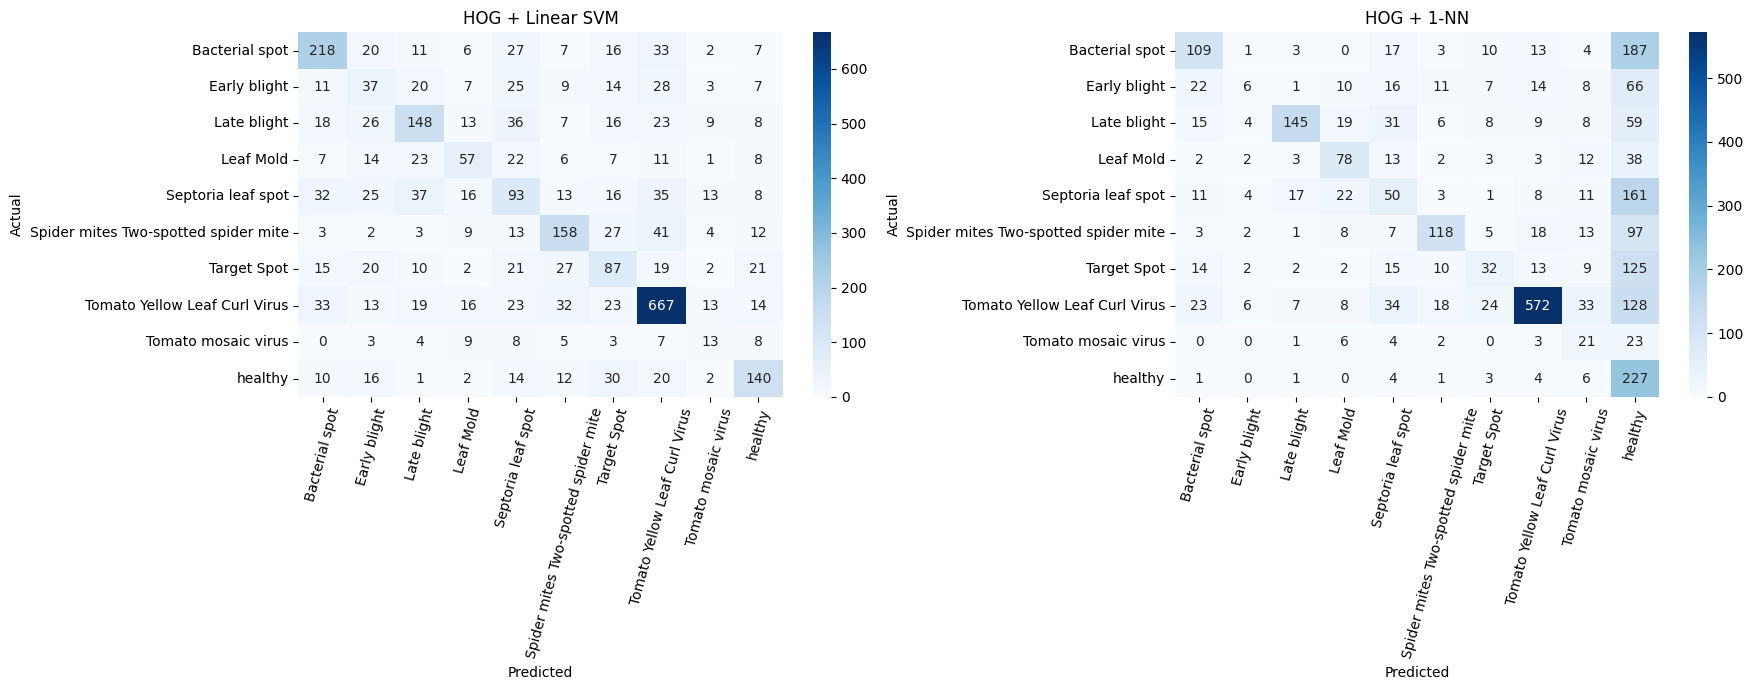

In [15]:
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

class_labels = [
    class_name.split("___", 1)[1].replace("_", " ")
    for class_name in tomato_data.classes
]

hog_models = {
    "HOG + Linear SVM": LinearSVC(
        C=1.0,
        dual="auto",
        max_iter=5000,
        random_state=42,
    ),
    "HOG + 1-NN": KNeighborsClassifier(
        n_neighbors=1,
        algorithm="brute",
        n_jobs=-1,
    ),
}

hog_val_predictions = {}
hog_val_results = {}

for name, classifier in hog_models.items():
    start = time.time()
    classifier.fit(X_train_hog, y_train_hog)
    predictions = classifier.predict(X_val_hog)
    elapsed = time.time() - start

    hog_val_predictions[name] = predictions
    hog_val_results[name] = {
        "accuracy": accuracy_score(y_val_hog, predictions),
        "macro_f1": f1_score(y_val_hog, predictions, average="macro"),
    }

    print(f"\n{name}")
    print(f"Accuracy: {hog_val_results[name]['accuracy']:.4f}")
    print(f"Macro F1: {hog_val_results[name]['macro_f1']:.4f}")
    print(f"Fit + validation time: {elapsed:.1f} seconds")
    print(classification_report(
        y_val_hog,
        predictions,
        labels=list(range(len(class_labels))),
        target_names=class_labels,
        zero_division=0,
    ))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, predictions) in zip(axes, hog_val_predictions.items()):
    cm = confusion_matrix(
        y_val_hog,
        predictions,
        labels=list(range(len(class_labels))),
    )
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=75)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
from pathlib import Path

print("Current folder:", Path.cwd())

for item in Path.cwd().iterdir():
    print(item.name)

Current folder: /content
.config
plantvillage_tomato
sample_data


In [17]:
from pathlib import Path

root = Path("/content/plantvillage_tomato")

for item in sorted(root.iterdir()):
    print("Folder:" if item.is_dir() else "File:  ", item.name)

Folder: .cache
Folder: raw


In [18]:
from pathlib import Path

root = Path("/content/plantvillage_tomato/raw")

for item in sorted(root.iterdir()):
    print("Folder:" if item.is_dir() else "File:  ", item.name)

Folder: color


In [19]:
from pathlib import Path

root = Path("/content/plantvillage_tomato/raw/color")

for item in sorted(root.iterdir()):
    print("Folder:" if item.is_dir() else "File:  ", item.name)

Folder: Tomato___Bacterial_spot
Folder: Tomato___Early_blight
Folder: Tomato___Late_blight
Folder: Tomato___Leaf_Mold
Folder: Tomato___Septoria_leaf_spot
Folder: Tomato___Spider_mites Two-spotted_spider_mite
Folder: Tomato___Target_Spot
Folder: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Folder: Tomato___Tomato_mosaic_virus
Folder: Tomato___healthy


In [20]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

root = Path("/content/plantvillage_tomato/raw/color")
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_paths = []
labels = []

for class_folder in sorted(root.iterdir()):
    if class_folder.is_dir():
        for image_path in class_folder.iterdir():
            if image_path.suffix.lower() in extensions:
                image_paths.append(str(image_path))
                labels.append(class_folder.name)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("\nValidation images per class:")
for class_name, count in sorted(Counter(val_labels).items()):
    print(class_name, count)

Training images: 14528
Validation images: 3632

Validation images per class:
Tomato___Bacterial_spot 425
Tomato___Early_blight 200
Tomato___Late_blight 382
Tomato___Leaf_Mold 191
Tomato___Septoria_leaf_spot 354
Tomato___Spider_mites Two-spotted_spider_mite 335
Tomato___Target_Spot 281
Tomato___Tomato_Yellow_Leaf_Curl_Virus 1071
Tomato___Tomato_mosaic_virus 75
Tomato___healthy 318


In [21]:
# Keep the current 3,632-image split aside for final testing
test_paths, test_labels = val_paths, val_labels

# Split the remaining images into training and validation sets
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths,
    train_labels,
    test_size=0.20,
    random_state=42,
    stratify=train_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Final test images:", len(test_paths))

Training images: 11622
Validation images: 2906
Final test images: 3632


In [22]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Create a consistent mapping from class names to integer labels
class_names = sorted(set(train_labels))
class_to_index = {name: index for index, name in enumerate(class_names)}

def make_dataset(paths, labels, training=False):
    integer_labels = [class_to_index[name] for name in labels]
    ds = tf.data.Dataset.from_tensor_slices((paths, integer_labels))

    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=42)

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

# Check one batch
images, labels = next(iter(train_ds))
print("Images:", images.shape)
print("Labels:", labels.shape)
print("Classes:", class_names)

Images: (32, 224, 224, 3)
Labels: (32,)
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [23]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

print("GPU devices:", tf.config.list_physical_devices("GPU"))

augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
364/364 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.6998 - loss: 0.9088 - val_accuracy: 0.8517 - val_loss: 0.4862 - learning_rate: 0.0010
Epoch 2/15
364/364 ━━━━━━━━━━━━━━━━━━━━ 33s 73ms/step - accuracy: 0.8290 - loss: 0.5157 - val_accuracy: 0.8692 - val_loss: 0.4182 - learning_rate: 0.0010
Epoch 3/15
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 72ms/step - accuracy: 0.8513 - loss: 0.4465 - val_accuracy: 0.8806 - val_loss: 0.3697 - learning_rate: 0.0010
Epoch 4/15
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 72ms/step - accuracy: 0.8598 - loss: 0.4150 - val_accuracy: 0.8799 - val_loss: 0.3664 - learning_rate: 0.0010
Epoch 5/15
364/364 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.8675 - loss: 0.3908 - val_accuracy: 0.8878 - val_loss: 0.3442 - learning_rate: 0.0010
Epoch 6/15
364/364 ━━━━━━━━━━━━━━━━━━━━ 27s 73ms/step - accuracy: 0.8742 - loss: 0.3726 - val_accurac

In [25]:
# Unfreeze the pretrained model, then freeze all but its last 30 layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 47s 102ms/step - accuracy: 0.9464 - loss: 0.1521 - val_accuracy: 0.9308 - val_loss: 0.2205 - learning_rate: 1.0000e-05
Epoch 2/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 33s 82ms/step - accuracy: 0.9528 - loss: 0.1380 - val_accuracy: 0.9449 - val_loss: 0.1769 - learning_rate: 1.0000e-05
Epoch 3/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.9541 - loss: 0.1351 - val_accuracy: 0.9322 - val_loss: 0.2317 - learning_rate: 1.0000e-05
Epoch 4/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - accuracy: 0.9565 - loss: 0.1261 - val_accuracy: 0.9456 - val_loss: 0.1842 - learning_rate: 1.0000e-05
Epoch 5/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 29s 80ms/step - accuracy: 0.9640 - loss: 0.0988 - val_accuracy: 0.9463 - val_loss: 0.1847 - learning_rate: 2.0000e-06


In [26]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

# True validation labels
y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

# Model predictions
probabilities = model.predict(val_ds)
y_pred = np.argmax(probabilities, axis=1)

print("Validation accuracy:", accuracy_score(y_true, y_pred))
print("Validation macro F1:", f1_score(y_true, y_pred, average="macro"))
print("\nPer-class results:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

91/91 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step
Validation accuracy: 0.9449415003441156
Validation macro F1: 0.9214437383907237

Per-class results:
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9754    0.9296    0.9520       341
                        Tomato___Early_blight     0.9194    0.7125    0.8028       160
                         Tomato___Late_blight     0.9641    0.9672    0.9656       305
                           Tomato___Leaf_Mold     0.9018    0.9671    0.9333       152
                  Tomato___Septoria_leaf_spot     0.9406    0.9505    0.9455       283
Tomato___Spider_mites Two-spotted_spider_mite     0.9442    0.8843    0.9133       268
                         Tomato___Target_Spot     0.7643    0.9511    0.8475       225
       Tomato___Tomato_Yellow_Leaf_Curl_Virus     0.9953    0.9930    0.9942       857
                 Tomato___Tomato_mosaic_virus     1.0000    0.8000    0.8889

In [27]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# Evaluate overall loss and accuracy
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

# Get detailed class-level results
y_test_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

test_probabilities = model.predict(test_ds)
y_test_pred = np.argmax(test_probabilities, axis=1)

print("Test accuracy:", accuracy_score(y_test_true, y_test_pred))
print("Test macro F1:", f1_score(y_test_true, y_test_pred, average="macro"))
print("\nPer-class test results:")
print(classification_report(
    y_test_true,
    y_test_pred,
    target_names=class_names,
    digits=4
))

114/114 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - accuracy: 0.9416 - loss: 0.1721
114/114 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step
Test accuracy: 0.9416299559471366
Test macro F1: 0.9197030698522726

Per-class test results:
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9685    0.9412    0.9547       425
                        Tomato___Early_blight     0.8712    0.7100    0.7824       200
                         Tomato___Late_blight     0.9583    0.9634    0.9608       382
                           Tomato___Leaf_Mold     0.9333    0.9529    0.9430       191
                  Tomato___Septoria_leaf_spot     0.9386    0.9068    0.9224       354
Tomato___Spider_mites Two-spotted_spider_mite     0.9551    0.8896    0.9212       335
                         Tomato___Target_Spot     0.7364    0.9644    0.8351       281
       Tomato___Tomato_Yellow_Leaf_Curl_Virus     0.9962    0.9897    0.9930      1071
     

In [28]:
import json

model.save("/content/tomato_mobilenetv2.keras")

with open("/content/tomato_class_names.json", "w") as f:
    json.dump(class_names, f)

from google.colab import files
files.download("/content/tomato_mobilenetv2.keras")
files.download("/content/tomato_class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>